In [15]:
# %pip install tensorflow matplotlib

In [16]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [17]:
#load MINST dataset

(x_train, y_train),(x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [18]:
x_train.shape

(60000, 28, 28)

In [19]:
#Normlize the images

x_train = x_train / 255.0
x_test = x_test / 255.0

In [20]:
#Reshape the images(28x28, 1 color chanel)

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [21]:
x_train.shape

(60000, 28, 28, 1)

In [22]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPool2D(2, 2), 
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

c:\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.fit(x_train, y_train,epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 19ms/step - accuracy: 0.9491 - loss: 0.1731
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 17ms/step - accuracy: 0.9819 - loss: 0.0622
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.9878 - loss: 0.0422
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9915 - loss: 0.0294
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 17ms/step - accuracy: 0.9943 - loss: 0.0204


In [24]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9854 - loss: 0.0468


In [27]:
prediction = model.predict(x_test[:1])
predicted_digit = prediction.argmax()
predicted_digit

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step


np.int64(7)

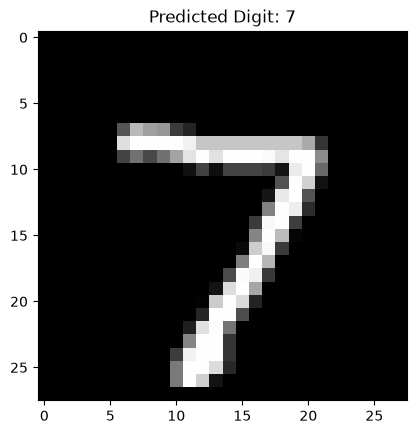

In [28]:
plt.imshow(x_test[0].reshape(28, 28, ), cmap='grey')
plt.title(f"Predicted Digit: {predicted_digit}")
plt.show()